# Steps to Perform 

Requirements for Passing:

1. Advanced SQL: Extract only "Active" users from the database using the most recent updated_at timestamp.
2. String Manipulation (Regex): Extract the Date, User ID, Product ID, and Euro Value from the raw text logs. Filter out rows labeled "ERROR".
3. Temporal Joins: Join the transactions to the exchange rate table based on the exact day. You must forward-fill the weekend exchange rates so transactions don't drop out.
4. Efficiency: Your code must run on all 100,000 rows in under 2 minutes. No for loops allowed in Pandas.
5. Dashboard: Build visualizations showing Total USD Revenue by Month and Top 5 Most Valuable Customers.

# Step1: Advanced SQL: Extract only "Active" users from the database using the most recent updated_at timestamp.

In [1]:
# Check the notebooks's current folder
import os
print(os.getcwd)

<built-in function getcwd>


In [2]:
#List the files in that folder
print(os.listdir())

['top_5_customers.csv', 'Enterprise_Data_Reconciliation_Project.ipynb', 'enterprise_data_reconciliation_project.zip', 'Student_work_file (1) (1).ipynb', 'server_logs (1) (1).txt', 'daily_exchange_rates (1) (1).csv', 'enterprise_database (1) (1).db', 'statement (1) (4).pdf', 'reconciled_transactions.csv', '.ipynb_checkpoints', 'project_results.zip']


In [3]:
# as project file name and other data appears , get the path name for the desired folder
""""
db_path = Path.cwd() / "enterprise_database (1) (1).db"
print(db_path)
""""

/Users/naziabanoosiddiqui/anaconda_projects/Enterprise Project-Intership Studio/enterprise_database (1) (1).db


In [6]:
with sqlite3.connect(db_path) as conn:
    tables = pd.read_sql_query(
        "SELECT name, type FROM sqlite_master WHERE type IN ('table', 'view');",
        conn
    )

print("Database file:", db_path)
print("File size (bytes):", db_path.stat().st_size)
print(tables)

Database file: /Users/naziabanoosiddiqui/anaconda_projects/Enterprise Project-Intership Studio/enterprise_database (1) (1).db
File size (bytes): 0
Empty DataFrame
Columns: [name, type]
Index: []


In [7]:
from pathlib import Path
import shutil

source_db = Path.home() / "Downloads" / "enterprise_database (1) (1).db"
project_db = Path.cwd() / "enterprise_database (1) (1).db"

print("Original found:", source_db.exists())
if source_db.exists():
    print("Original size:", source_db.stat().st_size, "bytes")
    shutil.copy2(source_db, project_db)
    print("Project copy size:", project_db.stat().st_size, "bytes")

Original found: True
Original size: 2670592 bytes
Project copy size: 2670592 bytes


In [8]:
with sqlite3.connect(db_path) as conn:
    tables = pd.read_sql_query(
        "SELECT name, type FROM sqlite_master WHERE type IN ('table', 'view');",
        conn
    )

print(tables)

    name   type
0  users  table


In [9]:

query = """
SELECT user_id, name,status,updated_at
FROM users
LIMIT 5;
"""

with sqlite3.connect(db_path) as conn:
    sample_users = pd.read_sql_query(query,conn)


sample_users

,user_id,name,status,updated_at
0,U-00000,User_U-00000,Pending,2023-01-01 10:00:00
1,U-00000,User_U-00000,Active,2023-01-19 14:00:00
2,U-00000,User_U-00000,Suspended,2023-02-28 09:00:00
3,U-00001,User_U-00001,Pending,2023-01-01 10:00:00
4,U-00001,User_U-00001,Active,2023-01-28 14:00:00


In [10]:
query_active = """
WITH ranked_users AS (
    SELECT
        user_id,
        name,
        status,
        updated_at,
        ROW_NUMBER() OVER (
            PARTITION BY user_id
            ORDER BY updated_at DESC
        ) AS row_num
    FROM users
)
SELECT user_id, name, status, updated_at
FROM ranked_users
WHERE row_num = 1
  AND status = 'Active';
"""

with sqlite3.connect(db_path) as conn:
    df_active_users = pd.read_sql_query(query_active, conn)

print("Active users:", len(df_active_users))
df_active_users.head()
               

Active users: 14183


,user_id,name,status,updated_at
0,U-00001,User_U-00001,Active,2023-01-28 14:00:00
1,U-00003,User_U-00003,Active,2023-01-22 14:00:00
2,U-00005,User_U-00005,Active,2023-01-17 14:00:00
3,U-00006,User_U-00006,Active,2023-01-05 14:00:00
4,U-00007,User_U-00007,Active,2023-01-27 14:00:00


# Step2: String Manipulation (Regex): Extract the Date, User ID, Product ID, and Euro Value from the raw text logs. Filter out rows labeled "ERROR".

This dataset contains 100,000 rows. Thus, on standard Pandas for
loops or iterrows() to parse the text or calculate the currency conversions, the script will time out or take hours to run. Hence, we need to apply vectorized operations.

In [11]:
data_dir = Path.cwd()
log_path = data_dir / "server_logs (1) (1).txt"

df_logs = pd.read_csv(log_path)

print("Rows and Columns:", df_logs.shape)
print("Columns:", df_logs.columns.tolist())
df_logs.head()

Rows and Columns: (100000, 1)
Columns: ['Raw_Server_Log']


,Raw_Server_Log
0,[2023-03-15 00:00:00] INFO: Transaction proces...
1,[2023-09-09 00:00:00] ERROR: Transaction proce...
2,[2023-05-09 00:00:00] INFO: Transaction proces...
3,[2023-10-21 00:00:00] INFO: Transaction proces...
4,[2023-01-10 00:00:00] INFO: Transaction proces...


In [12]:
#Count error records
is_error = df_logs["Raw_Server_Log"].str.contains("ERROR",na=False)
print("Error Records:", is_error.sum())
print("Records to parse:", (~is_error).sum())

Error Records: 5098
Records to parse: 94902


In [13]:
df_logs.loc[~is_error,"Raw_Server_Log"].iloc[0]

'[2023-03-15 00:00:00] INFO: Transaction processed. payload={"u":"U-19484", "item_code":"PRD-874", "eur_val":3404.44}'

In [14]:
print("Total:", len(df_logs))
print("Errors + Records to Parse:", is_error.sum() + (~is_error).sum())

Total: 100000
Errors + Records to Parse: 100000


In [15]:
#Keep only logs without ERROR
valid_logs = df_logs.loc[~is_error,"Raw_Server_Log"]

#Extract the four fields from each log
pattern = (
    r'\[(?P<Date>\d{4}-\d{2}-\d{2})'
    r'.*?"u":"(?P<User_ID>[^"]+)"'
    r'.*?"item_code":"(?P<Product_ID>[^"]+)"'
    r'.*?"eur_val":(?P<Euro_Value>[\d.]+)'
)

extracted_data = valid_logs.str.extract(pattern)

#Convert extracted values to useful types
extracted_data["Date"] = pd.to_datetime(extracted_data["Date"])
extracted_data["Euro_Value"] = pd.to_numeric(
    extracted_data["Euro_Value"],errors = "coerce"
)

print("Extracted rows and columns:", extracted_data.shape)
print("Rows with a missing extracted field:", extracted_data.isna().any(axis=1).sum())
extracted_data.head()


Extracted rows and columns: (94902, 4)
Rows with a missing extracted field: 0


,Date,User_ID,Product_ID,Euro_Value
0,2023-03-15,U-19484,PRD-874,3404.44
2,2023-05-09,U-18932,PRD-905,3406.21
3,2023-10-21,U-15882,PRD-284,164.08
4,2023-01-10,U-22781,PRD-665,26.80
5,2023-05-23,U-13348,PRD-589,4964.77


This is a regular expression (regex): a pattern that tells Python which parts of each text line to capture or is a pattern for finding text.

pattern = (
    r'\[(?P<Date>\d{4}-\d{2}-\d{2})'
    r'.*?"u":"(?P<User_ID>[^"]+)"'
    r'.*?"item_code":"(?P<Product_ID>[^"]+)"'
    r'.*?"eur_val":(?P<Euro_Value>[\d.]+)'
)

For a log like:
[2023-03-15 00:00:00] INFO: ... payload={"u":"U-19484", "item_code":"PRD-874", "eur_val":3404.44}

the regex captures:
- Date: 2023-03-15
- User_ID: U-19484
- Product_ID: PRD-874
- Euro_Value: 3404.44
The (?P<Name>...) parts name each captured value. The .*? sections skip over text between the fields.

# Step3:  Temporal Joins: Join the transactions to the exchange rate table based on the exact day. You must forward-fill the weekend exchange rates so transactions don't drop out.

In [16]:
rates_path = data_dir/ "daily_exchange_rates (1) (1).csv"

df_rates = pd.read_csv(rates_path)
df_rates["Date"] = pd.to_datetime(df_rates["Date"])

print("Rows:",len(df_rates))
print("Missing rates:", df_rates["EUR_to_USD"].isna().sum())
print("Date range:",df_rates["Date"].min(), "to", df_rates["Date"].max())

df_rates.head()

Rows: 365
Missing rates: 104
Date range: 2023-01-01 00:00:00 to 2023-12-31 00:00:00


,Date,EUR_to_USD
0,2023-01-01,1.124836
1,2023-01-02,1.093087
2,2023-01-03,1.132384
3,2023-01-04,1.176151
4,2023-01-05,1.088292


In [17]:
#confirm the missing values fall on weekends
missing = df_rates["EUR_to_USD"].isna()

print(
    df_rates.loc[missing,"Date"]
    .dt.day_name()
    .value_counts()
)

Date
Friday      52
Saturday    52
Name: count, dtype: int64


In [19]:
#Fill missing rates with the previous available rate
df_rates = df_rates.sort_values("Date").copy()
df_rates["EUR_to_USD"] = df_rates["EUR_to_USD"].ffill()

#Add the matching exchange rate to each transaction
transactions_with_rates = extracted_data.merge(
    df_rates[["Date", "EUR_to_USD"]],
    on="Date",
    how="left",
    validate="many_to_one"
)

print("Transactions:",len(extracted_data))
print("Transactions with no matched rate:",
      transactions_with_rates["EUR_to_USD"].isna().sum())

transactions_with_rates.head()

Transactions: 94902
Transactions with no matched rate: 0


,Date,User_ID,Product_ID,Euro_Value,EUR_to_USD
0,2023-03-15,U-19484,PRD-874,3404.44,1.178232
1,2023-05-09,U-18932,PRD-905,3406.21,1.104983
2,2023-10-21,U-15882,PRD-284,164.08,1.075350
3,2023-01-10,U-22781,PRD-665,26.80,1.127128
4,2023-05-23,U-13348,PRD-589,4964.77,1.019626


In [20]:
#Keep transactions  belonging to active users
df_final = transactions_with_rates.merge(
    df_active_users[["user_id","name"]],
    left_on = "User_ID",
    right_on = "user_id",
    how = "inner",
    validate = "many_to_one"
)

#Convert each transaction amount from EUR to USD
df_final["USD_Revenue"] = df_final["Euro_Value"] * df_final["EUR_to_USD"]

print("Transactions after active-user filter:",len(df_final))
print("Missing USD revenue:", df_final["USD_Revenue"].isna().sum())

df_final.head()

Transactions after active-user filter: 53899
Missing USD revenue: 0


,Date,User_ID,Product_ID,Euro_Value,EUR_to_USD,user_id,name,USD_Revenue
0,2023-03-15,U-19484,PRD-874,3404.44,1.178232,U-19484,User_U-19484,4011.220772
1,2023-10-21,U-15882,PRD-284,164.08,1.075350,U-15882,User_U-15882,176.443420
2,2023-01-10,U-22781,PRD-665,26.80,1.127128,U-22781,User_U-22781,30.207030
3,2023-10-20,U-22062,PRD-363,48.63,1.075350,U-22062,User_U-22062,52.294268
4,2023-12-02,U-22146,PRD-223,960.60,1.066142,U-22146,User_U-22146,1024.135923


# Step4: Efficiency: Your code must run on all 100,000 rows in under 2 minutes. No for loops allowed in Pandas.
Dashboard: Build visualizations showing Total USD Revenue by Month and Top 5 Most Valuable Customers.

In [21]:
#Revenue by month
df_final["Month"] = df_final["Date"].dt.to_period("M").astype(str)

monthly_revenue = (
    df_final.groupby("Month", as_index = False)["USD_Revenue"]
    .sum()
    .sort_values("Month")
)

#Top 5 Valuable customers by total USD revenue
top_customers = (
    df_final.groupby(["user_id", "name"], as_index=False)["USD_Revenue"]
    .sum()
    .sort_values("USD_Revenue",ascending=False)
    .head(5)
    .sort_values("USD_Revenue")
)

monthly_revenue

,Month,USD_Revenue
0,2023-01,1.284176e+07
1,2023-02,1.143613e+07
2,2023-03,1.234893e+07
3,2023-04,1.201538e+07
4,2023-05,1.233364e+07
5,2023-06,1.208436e+07
6,2023-07,1.244416e+07
7,2023-08,1.281273e+07
8,2023-09,1.222895e+07
9,2023-10,1.250133e+07


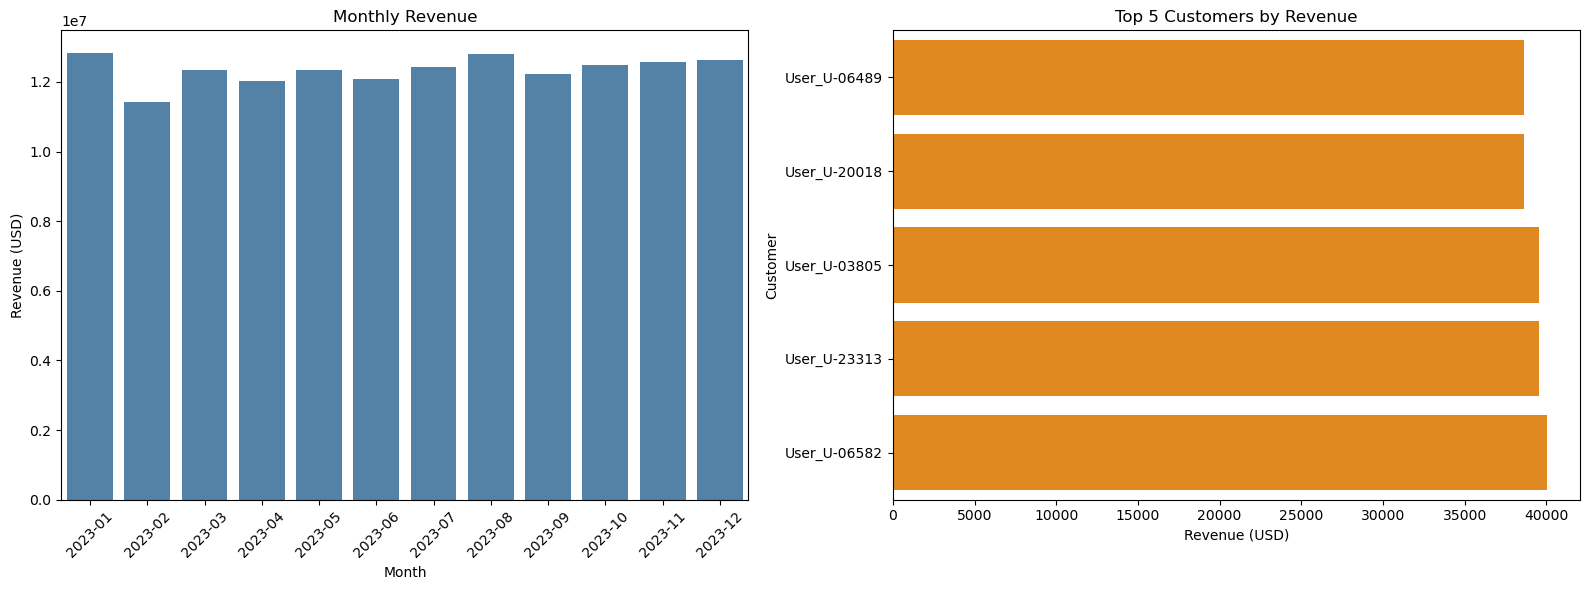

In [22]:
#Plot the summaries side by side
import matplotlib.pyplot as plt
import seaborn as sns

fig,axes = plt.subplots(1,2,figsize = (16,6))

sns.barplot(
    data = monthly_revenue,
    x="Month",
    y="USD_Revenue",
    ax=axes[0],
    color="steelblue"
)

axes[0].set_title("Monthly Revenue")
axes[0].set_xlabel("Month")
axes[0].set_ylabel("Revenue (USD)")
axes[0].tick_params(axis ="x", rotation = 45)



sns.barplot(
    data=top_customers,
    x="USD_Revenue",
    y="name",
    ax=axes[1],
    color="darkorange"
)
axes[1].set_title("Top 5 Customers by Revenue")
axes[1].set_xlabel("Revenue (USD)")
axes[1].set_ylabel("Customer")

plt.tight_layout()
plt.show()   

In [25]:
print("Final transaction rows:", len(df_final))
print("Unique users:", df_final["user_id"].nunique())
print("Date range:", df_final["Date"].min(), "to", df_final["Date"].max())
print("Missing key values:")
print(df_final[["User_ID", "Date", "Euro_Value", "EUR_to_USD", "USD_Revenue"]]
      .isna()
      .sum())

print("\nMonthly revenue:")
display(monthly_revenue)

print("\nTop 5 customers:")
display(top_customers)

Final transaction rows: 53899
Unique users: 13888
Date range: 2023-01-01 00:00:00 to 2023-12-31 00:00:00
Missing key values:
User_ID        0
Date           0
Euro_Value     0
EUR_to_USD     0
USD_Revenue    0
dtype: int64

Monthly revenue:


,Month,USD_Revenue
0,2023-01,1.284176e+07
1,2023-02,1.143613e+07
2,2023-03,1.234893e+07
3,2023-04,1.201538e+07
4,2023-05,1.233364e+07
5,2023-06,1.208436e+07
6,2023-07,1.244416e+07
7,2023-08,1.281273e+07
8,2023-09,1.222895e+07
9,2023-10,1.250133e+07



Top 5 customers:


,user_id,name,USD_Revenue
3553,U-06489,User_U-06489,38629.142146
11066,U-20018,User_U-20018,38649.965242
2078,U-03805,User_U-03805,39529.945085
12937,U-23313,User_U-23313,39555.806629
3613,U-06582,User_U-06582,40050.988262


In [26]:
df_final.to_csv("reconciled_transactions.csv", index=False)
monthly_revenue.to_csv("monthly_revenue.csv", index=False)
top_customers.to_csv("top_5_customers.csv", index=False)

In [27]:
print(Path.cwd())

/Users/naziabanoosiddiqui/anaconda_projects/Enterprise Project-Intership Studio


In [28]:
from pathlib import Path

output_dir = Path.cwd()
print(list(output_dir.glob("*.csv")))

[PosixPath('/Users/naziabanoosiddiqui/anaconda_projects/Enterprise Project-Intership Studio/top_5_customers.csv'), PosixPath('/Users/naziabanoosiddiqui/anaconda_projects/Enterprise Project-Intership Studio/monthly_revenue.csv'), PosixPath('/Users/naziabanoosiddiqui/anaconda_projects/Enterprise Project-Intership Studio/daily_exchange_rates (1) (1).csv'), PosixPath('/Users/naziabanoosiddiqui/anaconda_projects/Enterprise Project-Intership Studio/reconciled_transactions.csv')]


In [29]:
from pathlib import Path
from zipfile import ZipFile, ZIP_DEFLATED
from IPython.display import FileLink, display

project_dir = Path.cwd()
output_files = [
    project_dir / "reconciled_transactions.csv",
    project_dir / "monthly_revenue.csv",
    project_dir / "top_5_customers.csv",
]

# Check that all three files exist before creating the ZIP
missing = [file.name for file in output_files if not file.exists()]
if missing:
    raise FileNotFoundError(f"Could not find: {missing}")

zip_path = project_dir / "project_results.zip"

with ZipFile(zip_path, "w", ZIP_DEFLATED) as archive:
    for file in output_files:
        archive.write(file, arcname=file.name)

print(f"Created: {zip_path}")
display(FileLink(str(zip_path)))

Created: /Users/naziabanoosiddiqui/anaconda_projects/Enterprise Project-Intership Studio/project_results.zip


/Users/naziabanoosiddiqui/anaconda_projects/Enterprise Project-Intership Studio/project_results.zip

In [30]:
from IPython.display import FileLink, display

display(FileLink("project_results.zip"))

/Users/naziabanoosiddiqui/anaconda_projects/Enterprise Project-Intership Studio/project_results.zip

In [31]:
from pathlib import Path

zip_path = Path.cwd() / "project_results.zip"
print("Exists:", zip_path.exists())
print("Size:", zip_path.stat().st_size if zip_path.exists() else "not found")

Exists: True
Size: 1851499
